In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series analysis
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Forecasting models
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Visualization settings
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
sales = pd.read_csv("sales.csv")
stores = pd.read_csv("stores.csv")
features = pd.read_csv("features.csv")

print("Data loaded successfully")

Data loaded successfully


In [3]:
print("Sales dataset:", sales.shape)
print("Stores dataset:", stores.shape)
print("Features dataset:", features.shape)

display(sales.head())
display(stores.head())
display(features.head())

Sales dataset: (156000, 5)
Stores dataset: (50, 4)
Features dataset: (7800, 14)


,store_id,department,date,weekly_sales,is_holiday
0,1,1,2022-01-01,119075.96,1
1,1,2,2022-01-01,119107.85,1
2,1,3,2022-01-01,84369.88,1
3,1,4,2022-01-01,88445.24,1
4,1,5,2022-01-01,65159.85,1


,store_id,store_type,store_size,region
0,1,A,213810,North
1,2,C,31639,East
2,3,B,102098,South
3,4,B,88289,North
4,5,A,218696,North


,store_id,date,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday,holiday_name,season
0,1,2022-01-01,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2022-01-08,46.03,3.67,1356.75,2486.21,1427.01,983.27,2442.13,196.91,8.62,0,NaN,Winter
2,1,2022-01-15,25.96,5.46,3861.22,596.15,22.09,2854.11,3180.86,267.48,8.40,0,NaN,Winter
3,1,2022-01-22,25.92,3.58,579.35,2589.31,2493.19,1158.14,286.01,217.32,5.28,0,NaN,Winter
4,1,2022-01-29,78.37,4.41,4436.06,1416.64,478.38,2496.36,3423.53,247.35,8.40,0,NaN,Winter


In [4]:
print("Sales information:")
sales.info()

print("\nStores information:")
stores.info()

print("\nFeatures information:")
features.info()

Sales information:
<class 'pandas.DataFrame'>
RangeIndex: 156000 entries, 0 to 155999
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store_id      156000 non-null  int64  
 1   department    156000 non-null  int64  
 2   date          156000 non-null  str    
 3   weekly_sales  156000 non-null  float64
 4   is_holiday    156000 non-null  int64  
dtypes: float64(1), int64(3), str(1)
memory usage: 7.4 MB

Stores information:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   store_id    50 non-null     int64
 1   store_type  50 non-null     str  
 2   store_size  50 non-null     int64
 3   region      50 non-null     str  
dtypes: int64(2), str(2)
memory usage: 2.0 KB

Features information:
<class 'pandas.DataFrame'>
RangeIndex: 7800 entries, 0 to 7799
Data columns (total 14 columns):
 #   

In [5]:
print("Missing values in sales:")
print(sales.isnull().sum())

print("\nMissing values in stores:")
print(stores.isnull().sum())

print("\nMissing values in features:")
print(features.isnull().sum())

Missing values in sales:
store_id        0
department      0
date            0
weekly_sales    0
is_holiday      0
dtype: int64

Missing values in stores:
store_id      0
store_type    0
store_size    0
region        0
dtype: int64

Missing values in features:
store_id           0
date               0
temperature        0
fuel_price         0
markdown_1         0
markdown_2         0
markdown_3         0
markdown_4         0
markdown_5         0
cpi                0
unemployment       0
is_holiday         0
holiday_name    6900
season             0
dtype: int64


In [6]:
print("Duplicate rows in sales:", sales.duplicated().sum())
print("Duplicate rows in stores:", stores.duplicated().sum())
print("Duplicate rows in features:", features.duplicated().sum())

Duplicate rows in sales: 0
Duplicate rows in stores: 0
Duplicate rows in features: 0


In [7]:
sales["date"] = pd.to_datetime(sales["date"])
features["date"] = pd.to_datetime(features["date"])

print("Sales date range:", sales["date"].min(), "to", sales["date"].max())
print("Features date range:", features["date"].min(), "to", features["date"].max())

Sales date range: 2022-01-01 00:00:00 to 2024-12-21 00:00:00
Features date range: 2022-01-01 00:00:00 to 2024-12-21 00:00:00


In [8]:
print("Unique stores in sales:", sales["store_id"].nunique())
print("Unique departments:", sales["department"].nunique())
print("Unique sales dates:", sales["date"].nunique())

print("Unique stores in store metadata:", stores["store_id"].nunique())
print("Unique stores in features:", features["store_id"].nunique())

Unique stores in sales: 50
Unique departments: 20
Unique sales dates: 156
Unique stores in store metadata: 50
Unique stores in features: 50


In [9]:
print("Minimum weekly sales:", sales["weekly_sales"].min())
print("Maximum weekly sales:", sales["weekly_sales"].max())
print("Average weekly sales:", sales["weekly_sales"].mean())

print("Negative sales records:", (sales["weekly_sales"] < 0).sum())
print("Zero sales records:", (sales["weekly_sales"] == 0).sum())

Minimum weekly sales: 819.66
Maximum weekly sales: 505958.73
Average weekly sales: 56503.48880198719
Negative sales records: 0
Zero sales records: 0


In [10]:
# Merge using store_id and date
df = pd.merge(
    sales,
    features,
    on=["store_id", "date"],
    how="left",
    suffixes=("_sales", "_features")
)

print("Shape after merging sales and features:", df.shape)
display(df.head())

Shape after merging sales and features: (156000, 17)


,store_id,department,date,weekly_sales,is_holiday_sales,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday_features,holiday_name,season
0,1,1,2022-01-01,119075.96,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
1,1,2,2022-01-01,119107.85,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
2,1,3,2022-01-01,84369.88,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
3,1,4,2022-01-01,88445.24,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter
4,1,5,2022-01-01,65159.85,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter


In [11]:
df = pd.merge(
    df,
    stores,
    on="store_id",
    how="left"
)

print("Final dataset shape:", df.shape)
display(df.head())

Final dataset shape: (156000, 20)


,store_id,department,date,weekly_sales,is_holiday_sales,temperature,fuel_price,markdown_1,markdown_2,markdown_3,markdown_4,markdown_5,cpi,unemployment,is_holiday_features,holiday_name,season,store_type,store_size,region
0,1,1,2022-01-01,119075.96,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter,A,213810,North
1,1,2,2022-01-01,119107.85,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter,A,213810,North
2,1,3,2022-01-01,84369.88,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter,A,213810,North
3,1,4,2022-01-01,88445.24,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter,A,213810,North
4,1,5,2022-01-01,65159.85,1,97.57,4.83,10334.49,5905.86,5261.52,7098.43,876.08,203.52,3.32,1,New Year,Winter,A,213810,North


In [12]:
print("Missing values after merging:")
print(df.isnull().sum())

print("\nUnique stores:", df["store_id"].nunique())
print("Unique departments:", df["department"].nunique())
print("Unique dates:", df["date"].nunique())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

Missing values after merging:
store_id                    0
department                  0
date                        0
weekly_sales                0
is_holiday_sales            0
temperature                 0
fuel_price                  0
markdown_1                  0
markdown_2                  0
markdown_3                  0
markdown_4                  0
markdown_5                  0
cpi                         0
unemployment                0
is_holiday_features         0
holiday_name           138000
season                      0
store_type                  0
store_size                  0
region                      0
dtype: int64

Unique stores: 50
Unique departments: 20
Unique dates: 156

Date range:
2022-01-01 00:00:00 to 2024-12-21 00:00:00


In [13]:
df.to_csv("retail_sales_merged.csv", index=False)

print("Merged dataset saved successfully")

Merged dataset saved successfully


In [14]:
print("Sales Summary:")
display(df["weekly_sales"].describe())

print("\nTotal Sales:", df["weekly_sales"].sum())
print("Average Sales:", df["weekly_sales"].mean())
print("Median Sales:", df["weekly_sales"].median())

Sales Summary:


count    156000.000000
mean      56503.488802
std       46717.490663
min         819.660000
25%       21255.962500
50%       43394.870000
75%       79604.107500
max      505958.730000
Name: weekly_sales, dtype: float64


Total Sales: 8814544253.11
Average Sales: 56503.48880198719
Median Sales: 43394.869999999995


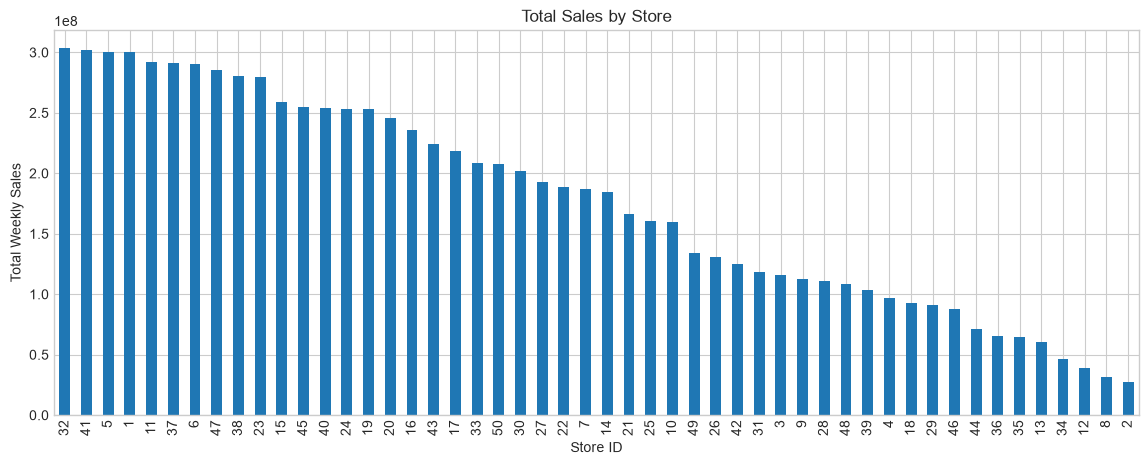

In [15]:
store_sales = (
    df.groupby("store_id")["weekly_sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 5))
store_sales.plot(kind="bar")

plt.title("Total Sales by Store")
plt.xlabel("Store ID")
plt.ylabel("Total Weekly Sales")
plt.xticks(rotation=90)
plt.show()

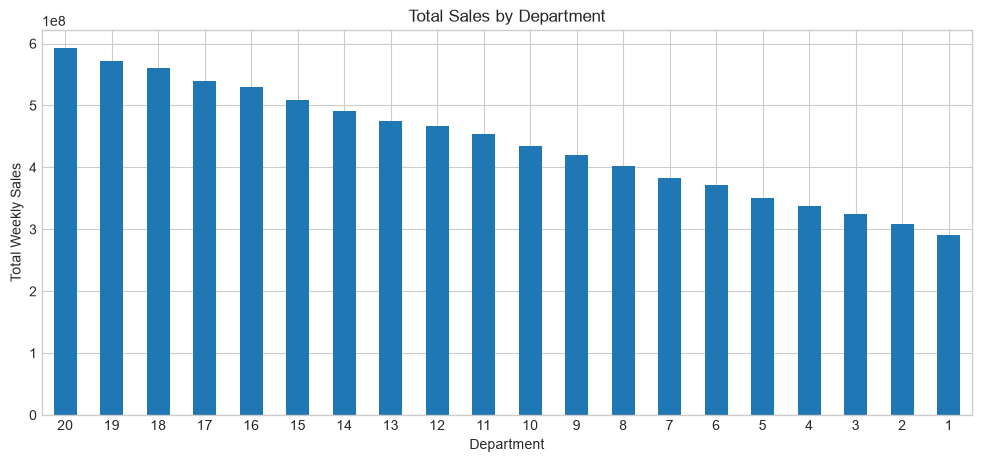

In [16]:
department_sales = (
    df.groupby("department")["weekly_sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))
department_sales.plot(kind="bar")

plt.title("Total Sales by Department")
plt.xlabel("Department")
plt.ylabel("Total Weekly Sales")
plt.xticks(rotation=0)
plt.show()

is_holiday_sales
0    52852.575328
1    84493.825439
Name: weekly_sales, dtype: float64


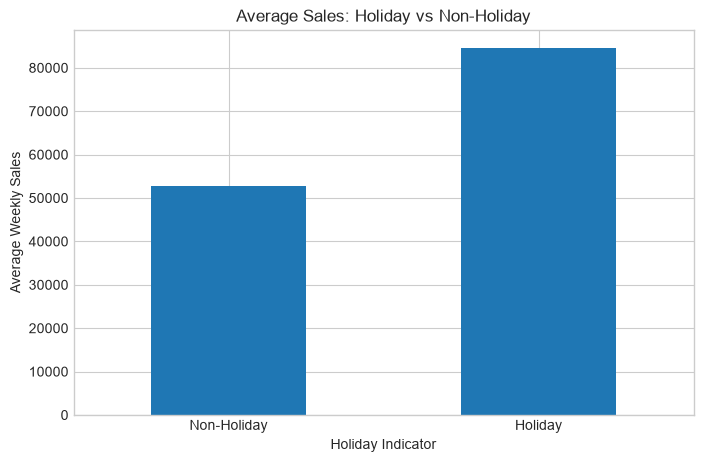

In [17]:
holiday_sales = df.groupby("is_holiday_sales")["weekly_sales"].mean()

print(holiday_sales)

holiday_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Average Sales: Holiday vs Non-Holiday")
plt.xlabel("Holiday Indicator")
plt.ylabel("Average Weekly Sales")
plt.xticks([0, 1], ["Non-Holiday", "Holiday"], rotation=0)
plt.show()

store_type
A    80066.725003
B    38353.554613
C    16222.839528
Name: weekly_sales, dtype: float64


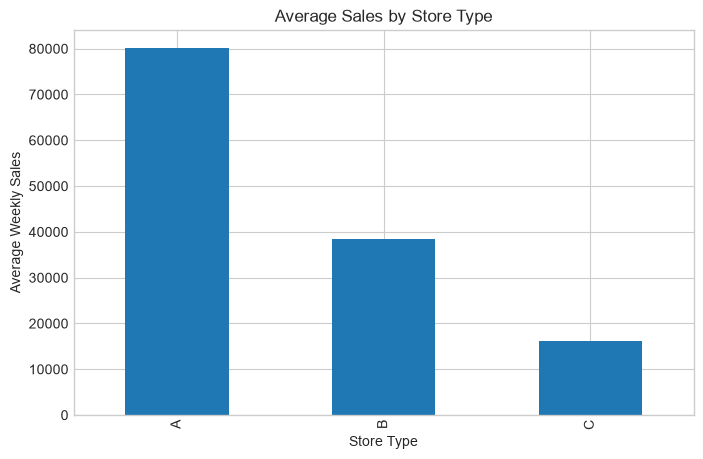

In [18]:
store_type_sales = df.groupby("store_type")["weekly_sales"].mean()

print(store_type_sales)

store_type_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Weekly Sales")
plt.show()

In [19]:
# Aggregate sales across all stores and departments
weekly_sales = (
    df.groupby("date")["weekly_sales"]
    .sum()
    .sort_index()
)

# Set weekly frequency
weekly_sales = weekly_sales.asfreq("W-SAT")

print("Number of weekly observations:", len(weekly_sales))
print("Start date:", weekly_sales.index.min())
print("End date:", weekly_sales.index.max())

display(weekly_sales.head())

Number of weekly observations: 156
Start date: 2022-01-01 00:00:00
End date: 2024-12-21 00:00:00


date
2022-01-01    70902987.20
2022-01-08    56437421.26
2022-01-15    55090458.09
2022-01-22    56719185.29
2022-01-29    55336034.35
Freq: W-SAT, Name: weekly_sales, dtype: float64

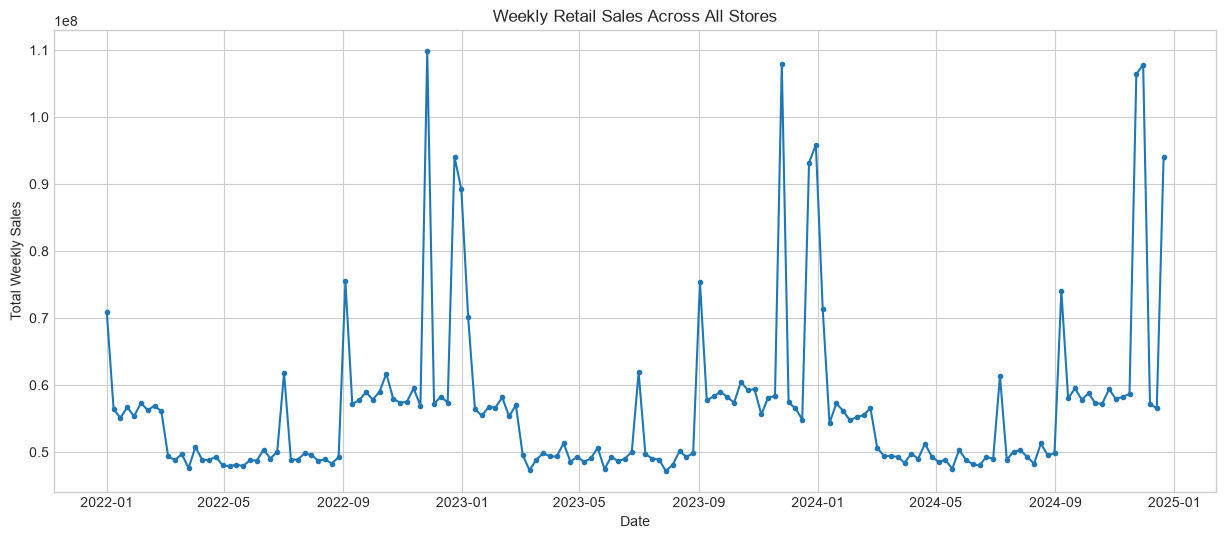

In [20]:
plt.figure(figsize=(15, 6))

plt.plot(
    weekly_sales.index,
    weekly_sales.values,
    marker="o",
    markersize=3
)

plt.title("Weekly Retail Sales Across All Stores")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.grid(True)

plt.show()

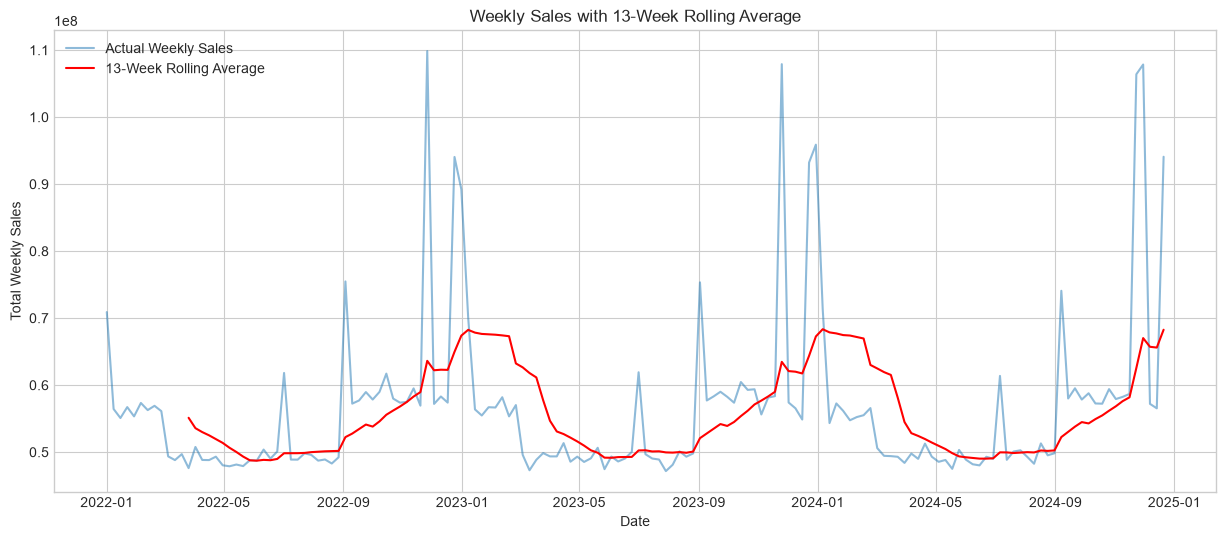

In [21]:
rolling_mean = weekly_sales.rolling(window=13).mean()

plt.figure(figsize=(15, 6))

plt.plot(
    weekly_sales.index,
    weekly_sales,
    label="Actual Weekly Sales",
    alpha=0.5
)

plt.plot(
    rolling_mean.index,
    rolling_mean,
    label="13-Week Rolling Average",
    color="red"
)

plt.title("Weekly Sales with 13-Week Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.grid(True)

plt.show()

In [22]:
print("Mean weekly sales:", weekly_sales.mean())
print("Median weekly sales:", weekly_sales.median())
print("Standard deviation:", weekly_sales.std())
print("Minimum weekly sales:", weekly_sales.min())
print("Maximum weekly sales:", weekly_sales.max())

Mean weekly sales: 56503488.80198717
Median weekly sales: 54810960.055
Standard deviation: 12304551.141789686
Minimum weekly sales: 47170184.1
Maximum weekly sales: 109851797.54


In [23]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    weekly_sales,
    model="additive",
    period=52
)

trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

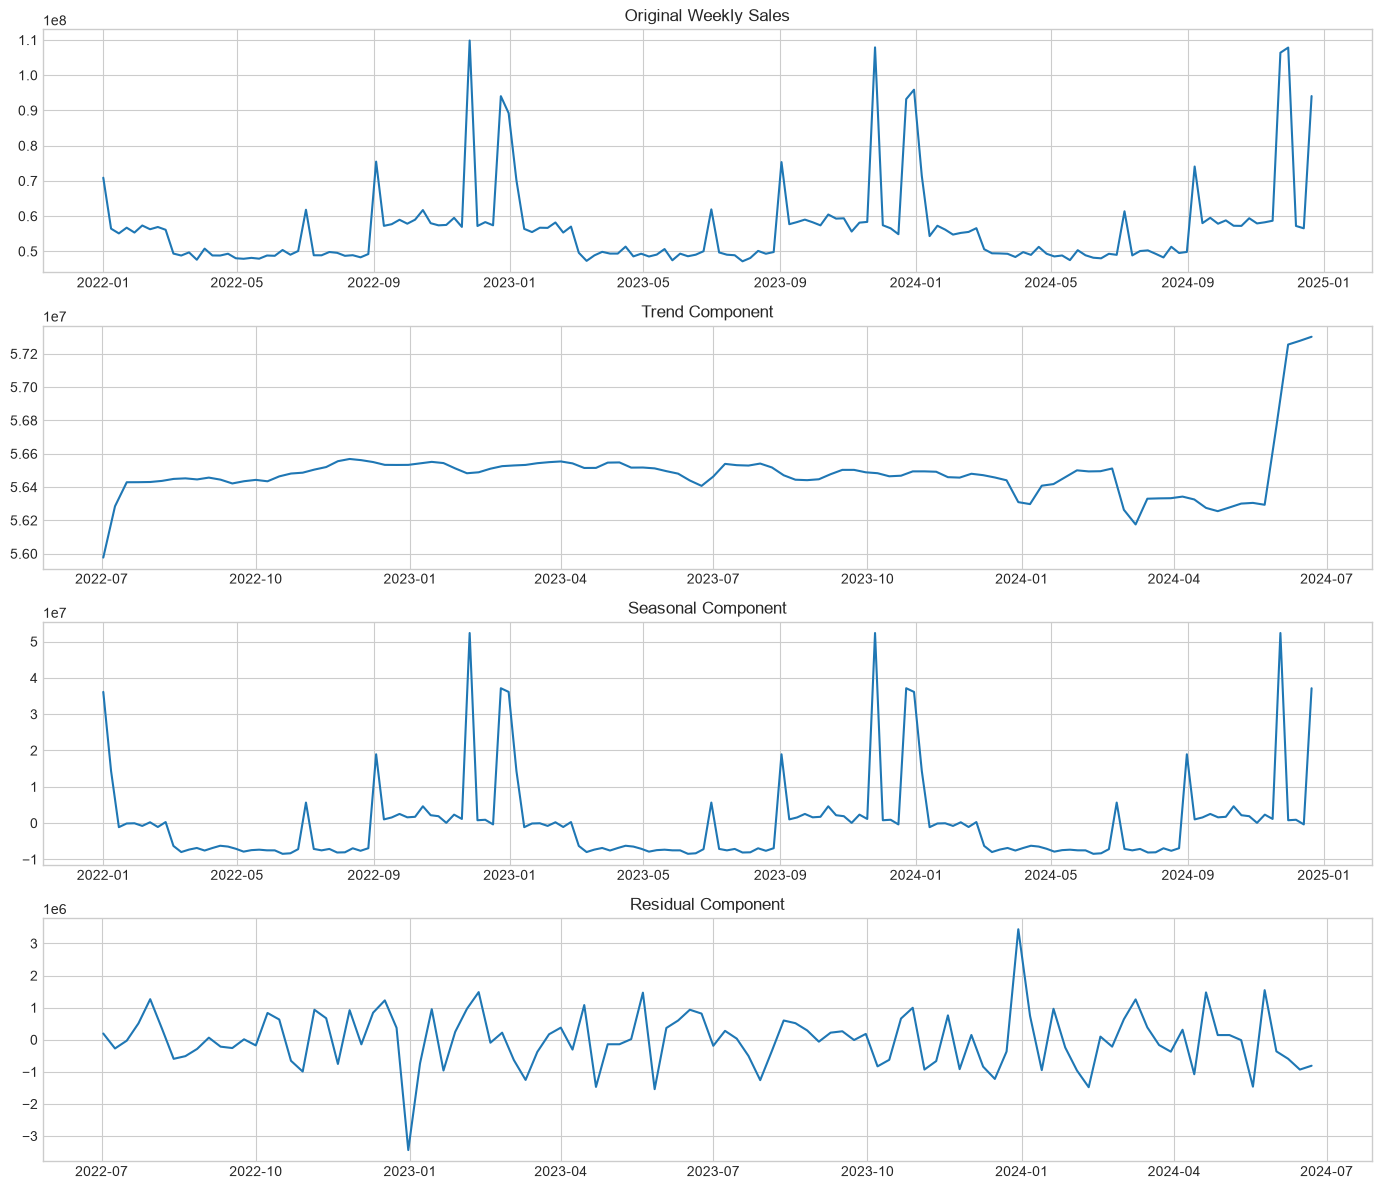

In [24]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12))

axes[0].plot(weekly_sales)
axes[0].set_title("Original Weekly Sales")

axes[1].plot(trend)
axes[1].set_title("Trend Component")

axes[2].plot(seasonal)
axes[2].set_title("Seasonal Component")

axes[3].plot(residual)
axes[3].set_title("Residual Component")

plt.tight_layout()
plt.show()

In [25]:
print("Trend component:")
print("Start:", trend.dropna().iloc[0])
print("End:", trend.dropna().iloc[-1])

print("\nSeasonal component:")
print("Minimum:", seasonal.min())
print("Maximum:", seasonal.max())

print("\nResidual component:")
print("Mean:", residual.mean())
print("Standard deviation:", residual.std())

Trend component:
Start: 55976839.987980776
End: 57302320.784326926

Seasonal component:
Minimum: -8470895.181682691
Maximum: 52362047.09649038

Residual component:
Mean: 1904.3949038426194
Standard deviation: 884634.6398429517


In [26]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(weekly_sales)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: -2.326806403448447
p-value: 0.16346805284952526
Critical Values:
1%: -3.474120870218417
5%: -2.880749791423677
10%: -2.5770126333102494


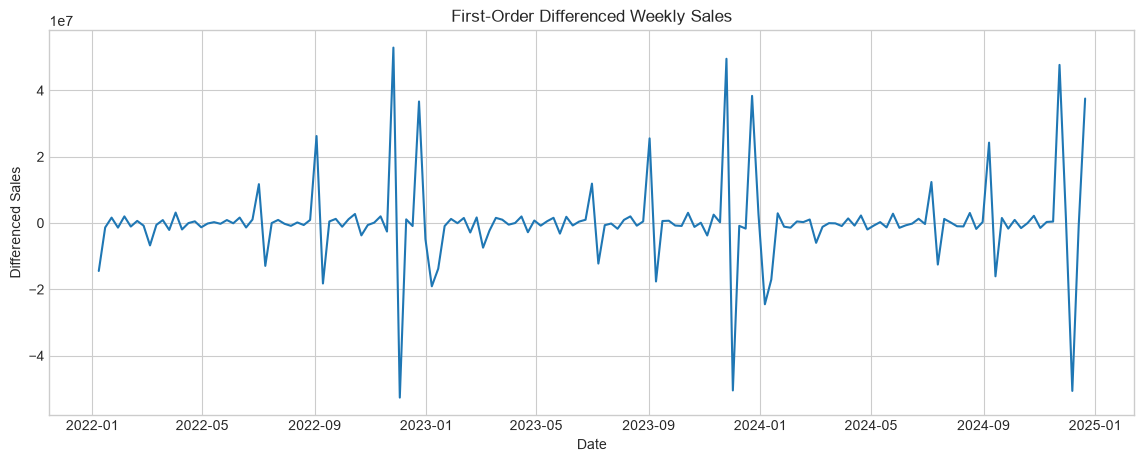

In [28]:
weekly_diff = weekly_sales.diff().dropna()

plt.figure(figsize=(14, 5))

plt.plot(weekly_diff)

plt.title("First-Order Differenced Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Differenced Sales")
plt.grid(True)

plt.show()

In [29]:
adf_diff = adfuller(weekly_diff)

print("ADF Statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

for key, value in adf_diff[4].items():
    print(f"{key}: {value}")

ADF Statistic: -10.70130232794036
p-value: 3.5177044463299077e-19
1%: -3.4744158894942156
5%: -2.880878382771059
10%: -2.577081275821236


<Figure size 1200x500 with 0 Axes>

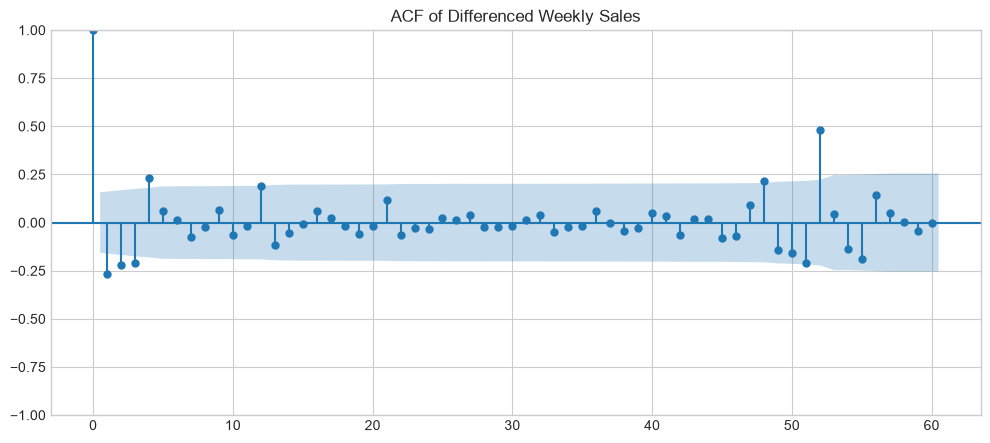

In [30]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))

plot_acf(
    weekly_diff,
    lags=60,
    alpha=0.05
)

plt.title("ACF of Differenced Weekly Sales")
plt.show()

<Figure size 1200x500 with 0 Axes>

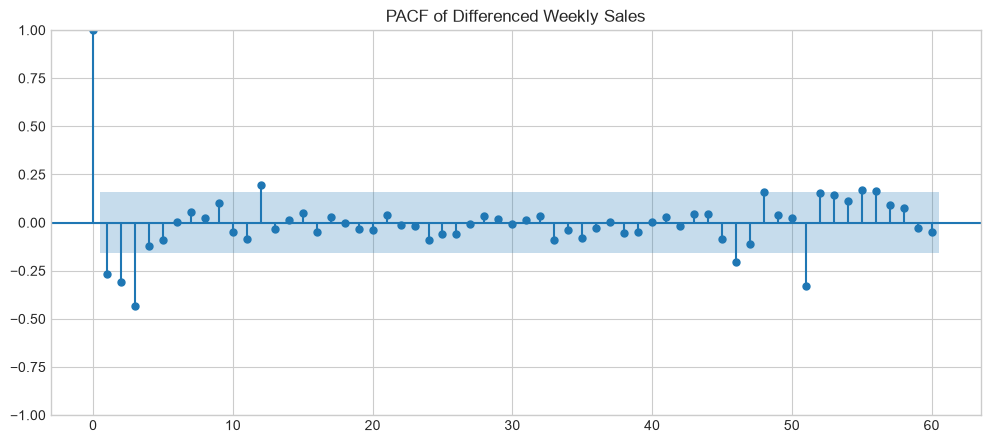

In [31]:
from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(12, 5))

plot_pacf(
    weekly_diff,
    lags=60,
    method="ywm",
    alpha=0.05
)

plt.title("PACF of Differenced Weekly Sales")
plt.show()

In [32]:
# Forecast horizon: 13 weeks
test_size = 13

train = weekly_sales.iloc[:-test_size]
test = weekly_sales.iloc[-test_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 143
Testing observations: 13

Training period:
2022-01-01 00:00:00 to 2024-09-21 00:00:00

Testing period:
2024-09-28 00:00:00 to 2024-12-21 00:00:00


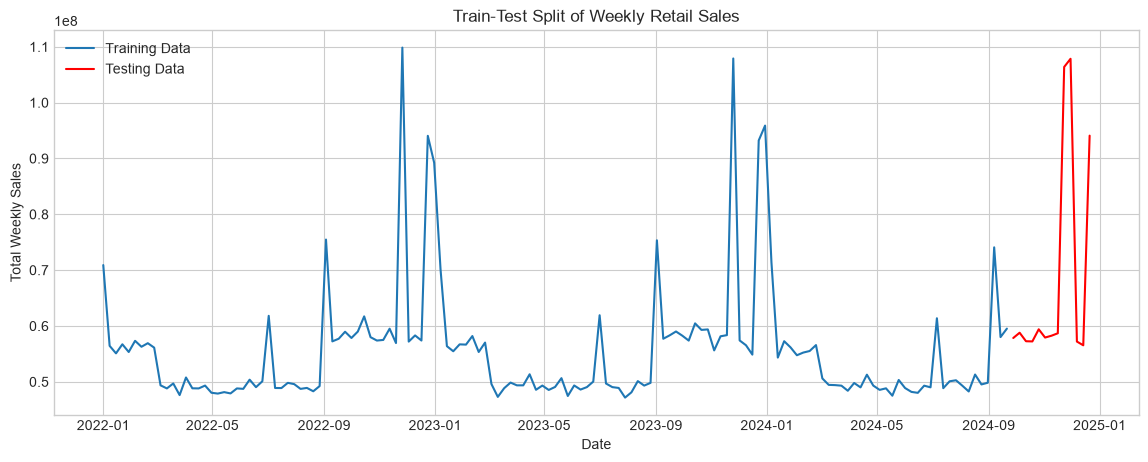

In [33]:
plt.figure(figsize=(14, 5))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Testing Data", color="red")

plt.title("Train-Test Split of Weekly Retail Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.grid(True)

plt.show()

In [34]:
# Seasonal naive forecast using the same week last year
seasonal_naive_forecast = weekly_sales.iloc[-test_size-52:-52].values

seasonal_naive_forecast = pd.Series(
    seasonal_naive_forecast,
    index=test.index
)

print("Seasonal naive forecast:")
display(seasonal_naive_forecast)

Seasonal naive forecast:


date
2024-09-28    5.825358e+07
2024-10-05    5.737800e+07
2024-10-12    6.046165e+07
2024-10-19    5.929284e+07
2024-10-26    5.938080e+07
2024-11-02    5.562284e+07
2024-11-09    5.814685e+07
2024-11-16    5.835613e+07
2024-11-23    1.079015e+08
2024-11-30    5.740765e+07
2024-12-07    5.654359e+07
2024-12-14    5.486677e+07
2024-12-21    9.321915e+07
Freq: W-SAT, dtype: float64

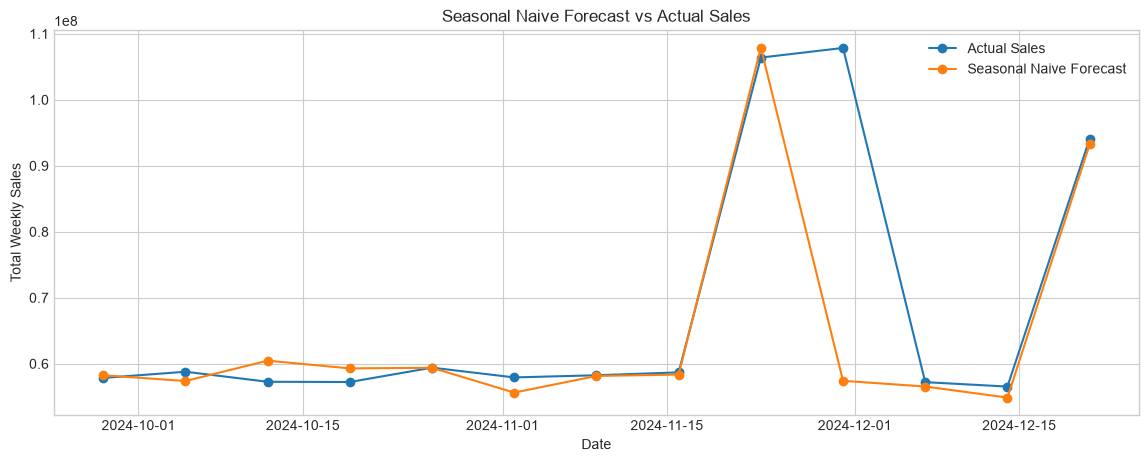

In [35]:
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Actual Sales", marker="o")
plt.plot(
    seasonal_naive_forecast.index,
    seasonal_naive_forecast,
    label="Seasonal Naive Forecast",
    marker="o"
)

plt.title("Seasonal Naive Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.grid(True)

plt.show()

In [36]:
mae_naive = mean_absolute_error(
    test,
    seasonal_naive_forecast
)

rmse_naive = np.sqrt(
    mean_squared_error(test, seasonal_naive_forecast)
)

mape_naive = mean_absolute_percentage_error(
    test,
    seasonal_naive_forecast
) * 100

print("Seasonal Naive Model")
print("MAE:", mae_naive)
print("RMSE:", rmse_naive)
print("MAPE:", mape_naive)

Seasonal Naive Model
MAE: 4999066.30076923
RMSE: 14067578.207390124
MAPE: 5.405234073145775


In [37]:
from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA model using training data
arima_model = ARIMA(
    train,
    order=(1, 1, 1)
)

arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:           weekly_sales   No. Observations:                  143
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2488.173
Date:                Sat, 31 Oct 2026   AIC                           4982.345
Time:                        20:47:49   BIC                           4991.213
Sample:                    01-01-2022   HQIC                          4985.949
                         - 09-21-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1948      0.094      2.075      0.038       0.011       0.379
ma.L1         -0.7948      0.082     -9.652      0.000      -0.956      -0.633
sigma2      9.775e+13        nan        nan        n

In [38]:
arima_forecast = arima_fit.forecast(steps=len(test))

arima_forecast = pd.Series(
    arima_forecast.values,
    index=test.index
)

display(arima_forecast)

date
2024-09-28    5.717071e+07
2024-10-05    5.671203e+07
2024-10-12    5.662268e+07
2024-10-19    5.660528e+07
2024-10-26    5.660189e+07
2024-11-02    5.660123e+07
2024-11-09    5.660110e+07
2024-11-16    5.660108e+07
2024-11-23    5.660107e+07
2024-11-30    5.660107e+07
2024-12-07    5.660107e+07
2024-12-14    5.660107e+07
2024-12-21    5.660107e+07
Freq: W-SAT, dtype: float64

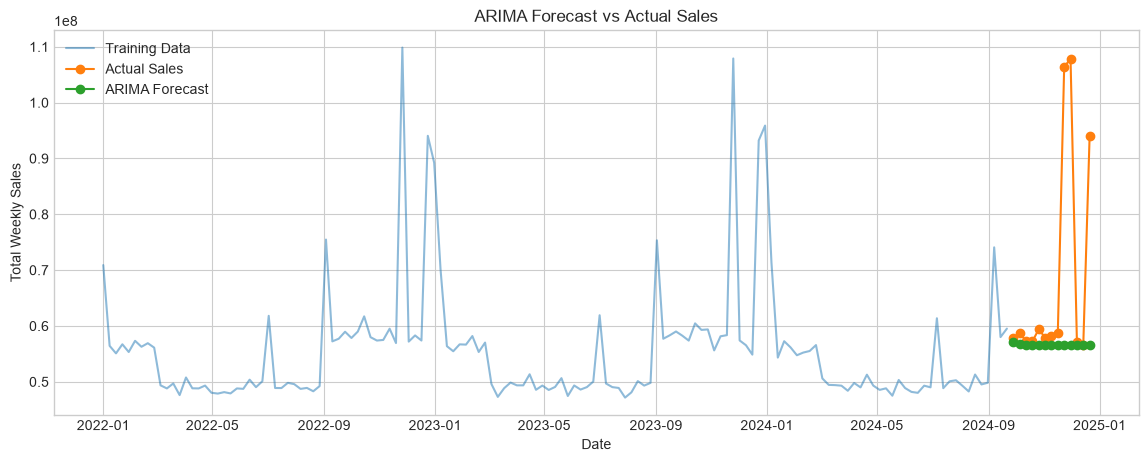

In [39]:
plt.figure(figsize=(14, 5))

plt.plot(train.index, train, label="Training Data", alpha=0.5)
plt.plot(test.index, test, label="Actual Sales", marker="o")
plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast",
    marker="o"
)

plt.title("ARIMA Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.legend()
plt.grid(True)

plt.show()

In [40]:
mae_arima = mean_absolute_error(test, arima_forecast)

rmse_arima = np.sqrt(
    mean_squared_error(test, arima_forecast)
)

mape_arima = mean_absolute_percentage_error(
    test, arima_forecast
) * 100

print("ARIMA Model")
print("MAE:", mae_arima)
print("RMSE:", rmse_arima)
print("MAPE:", mape_arima)


ARIMA Model
MAE: 11620019.032967402
RMSE: 22416552.920598876
MAPE: 11.970641303085799


In [45]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Train date range:", train.index.min(), "to", train.index.max())

print("Starting SARIMA fit...")

Train shape: (143,)
Test shape: (13,)
Train date range: 2022-01-01 00:00:00 to 2024-09-21 00:00:00
Starting SARIMA fit...


In [46]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

print("Fitting SARIMA...")
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(0, 1, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=True, maxiter=50)
print("Fit complete.")
print(sarima_fit.summary())

Fitting SARIMA...
Fit complete.
                                     SARIMAX Results                                      
Dep. Variable:                       weekly_sales   No. Observations:                  143
Model:             SARIMAX(1, 1, 1)x(0, 1, 1, 52)   Log Likelihood                -606.821
Date:                            Sat, 31 Oct 2026   AIC                           1221.641
Time:                                    20:53:19   BIC                           1227.975
Sample:                                01-01-2022   HQIC                          1223.852
                                     - 09-21-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4045      0.076     -5.301      0.000      -0.554      -0.255
ma.

SARIMA MAE:  9,641,851.27
SARIMA RMSE: 16,942,877.94
SARIMA MAPE: 11.13%


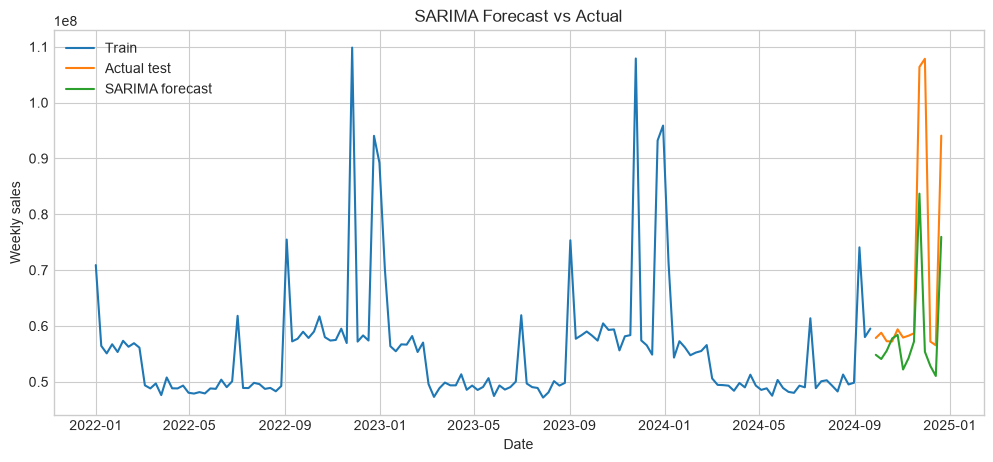

In [47]:
sarima_forecast = pd.Series(
    sarima_fit.forecast(steps=len(test)).values,
    index=test.index
)

mae = mean_absolute_error(test, sarima_forecast)
rmse = np.sqrt(mean_squared_error(test, sarima_forecast))
mape = (np.abs((test - sarima_forecast) / test)).mean() * 100

print(f"SARIMA MAE:  {mae:,.2f}")
print(f"SARIMA RMSE: {rmse:,.2f}")
print(f"SARIMA MAPE: {mape:.2f}%")

plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual test")
plt.plot(sarima_forecast.index, sarima_forecast, label="SARIMA forecast")
plt.title("SARIMA Forecast vs Actual")
plt.xlabel("Date")
plt.ylabel("Weekly sales")
plt.legend()
plt.show()

In [51]:
comparison = pd.DataFrame({
    "Model": ["Seasonal naive", "ARIMA(1,1,1)", "SARIMA(1,1,1)(0,1,1,52)"],
    "MAE": [4_999_066.30, 11_620_019.03, 9_641_851.27],
    "RMSE": [14_067_578.21, 22_416_552.92, 16_942_877.94],
    "MAPE (%)": [5.41, 11.97, 11.13]
})
comparison = comparison.sort_values("MAPE (%)").reset_index(drop=True)
comparison


,Model,MAE,RMSE,MAPE (%)
0,Seasonal naive,4999066.30,14067578.21,5.41
1,"SARIMA(1,1,1)(0,1,1,52)",9641851.27,16942877.94,11.13
2,"ARIMA(1,1,1)",11620019.03,22416552.92,11.97


Mean error: 3894019.4515384613
Error standard deviation: 14069866.733309316


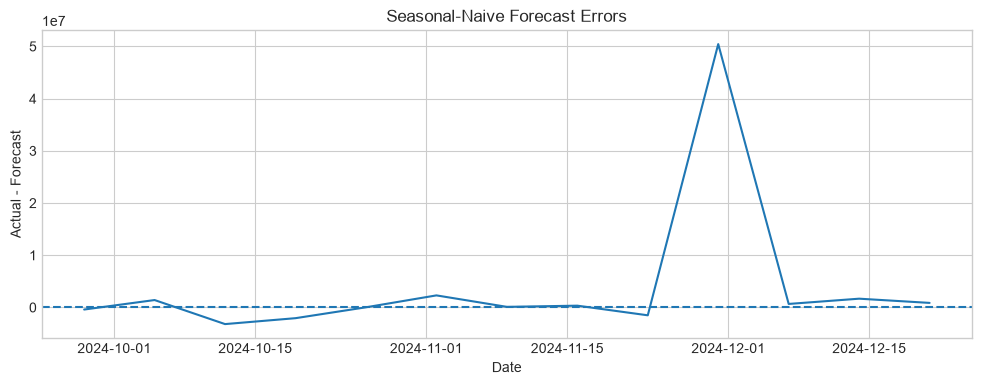

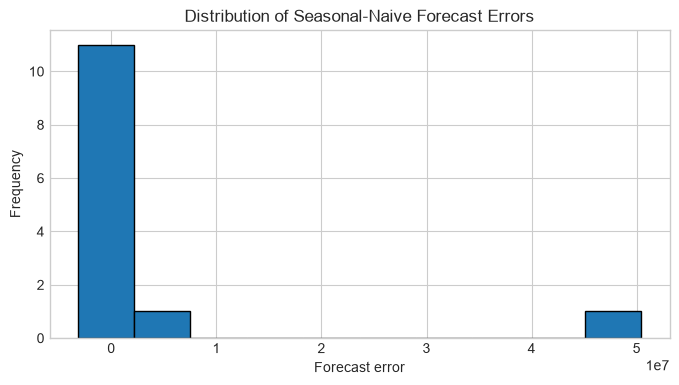

In [52]:
# Seasonal-naive forecast errors on the test period
seasonal_naive_errors = test - seasonal_naive_forecast

print("Mean error:", seasonal_naive_errors.mean())
print("Error standard deviation:", seasonal_naive_errors.std())

plt.figure(figsize=(12, 4))
plt.plot(seasonal_naive_errors.index, seasonal_naive_errors)
plt.axhline(0, linestyle="--")
plt.title("Seasonal-Naive Forecast Errors")
plt.xlabel("Date")
plt.ylabel("Actual - Forecast")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(seasonal_naive_errors, bins=10, edgecolor="black")
plt.title("Distribution of Seasonal-Naive Forecast Errors")
plt.xlabel("Forecast error")
plt.ylabel("Frequency")
plt.show()

In [53]:
error_check = pd.DataFrame({
    "actual": test,
    "forecast": seasonal_naive_forecast,
    "error": seasonal_naive_errors
})

error_check["abs_error"] = error_check["error"].abs()
error_check.sort_values("abs_error", ascending=False).head(5)

,actual,forecast,error,abs_error
date,,,,
2024-11-30,1.078491e+08,57407651.74,50441443.31,50441443.31
2024-10-12,5.726413e+07,60461654.33,-3197524.26,3197524.26
2024-11-02,5.792428e+07,55622842.56,2301437.60,2301437.60
2024-10-19,5.722914e+07,59292837.81,-2063699.18,2063699.18
2024-12-14,5.653709e+07,54866768.40,1670326.22,1670326.22
